# Previsor de Viralidade
### Um modelo de *machine learning* que estima se um vídeo curto tem chance de viralizar

**Autor:** Daniel Pugliezi · **Disciplina:** Computer Science · **Ferramentas:** Python, pandas, scikit-learn, matplotlib

---

**Pergunta do projeto:** olhando só para *como o vídeo foi feito* (o gancho, a estrutura e o conteúdo), dá para prever se ele vai viralizar?

| Etapa | O que acontece | Seção |
|---|---|---|
| 1 | Entender o problema e o que é machine learning | [1](#1) |
| 2 | Montar o conjunto de dados | [2](#2) |
| 3 | Explorar os dados com gráficos | [3](#3) |
| 4 | Criar novas variáveis (*feature engineering*) | [4](#4) |
| 5 | Separar treino e teste | [5](#5) |
| 6 | Preparar os dados para o modelo | [6](#6) |
| 7 | Treinar 4 modelos e comparar | [7](#7) |
| 8 | Avaliar o melhor modelo a fundo | [8](#8) |
| 9 | Entender **por que** o modelo decide | [9](#9) |
| 10 | Prever um vídeo novo | [10](#10) |
| 11 | Exportar o modelo para o site | [11](#11) |
| 12 | Limitações e próximos passos | [12](#12) |

<a id="1"></a>
## 1. O problema

### O que é machine learning?
Num programa normal, **nós escrevemos as regras**: `se o gancho demora mais de 3 segundos, então o vídeo é ruim`.

Em machine learning, invertemos isso: **damos exemplos e o computador descobre as regras sozinho**.

```
Programação tradicional:   regras + dados      →  resposta
Machine learning:          dados  + respostas  →  regras (o "modelo")
```

### Que tipo de problema é este?
- **Supervisionado**: cada vídeo de treino já vem com a resposta certa (viralizou ou não). O modelo aprende comparando o que ele chutou com a resposta.
- **Classificação binária**: a resposta tem só duas classes, `1 = viral` e `0 = não viral`.
- Além da classe, queremos uma **probabilidade** ("este vídeo tem 63% de chance"), que é muito mais útil para um criador de conteúdo.

### Vocabulário que vai aparecer o tempo todo
| Termo | Significado neste projeto |
|---|---|
| **Amostra / linha** | um vídeo |
| **Feature (variável)** | uma característica do vídeo, ex.: segundos até o gancho |
| **Target (alvo)** | o que queremos prever: `viral` |
| **Modelo** | a "fórmula" que o computador aprende |
| **Treino** | a fase em que o modelo ajusta seus números olhando os exemplos |
| **Teste** | vídeos que o modelo **nunca viu**, usados para medir se ele aprendeu de verdade |

In [1]:
# Bibliotecas
import numpy as np                 # contas com vetores e números aleatórios
import pandas as pd                # tabelas (DataFrames)
import matplotlib.pyplot as plt    # gráficos
import json, os

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve)

# Semente: deixa todos os sorteios reproduzíveis (mesmo resultado sempre que rodar)
SEED = 42

# Estilo dos gráficos (mesma paleta do site)
TINTA, PAPEL, SINAL, CINZA = "#1d1b2e", "#f6f5f1", "#e2462c", "#8a879c"
plt.rcParams.update({
    "figure.facecolor": PAPEL, "axes.facecolor": PAPEL, "axes.edgecolor": TINTA,
    "axes.labelcolor": TINTA, "xtick.color": TINTA, "ytick.color": TINTA,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 11,
    "axes.titleweight": "bold", "axes.titlesize": 13, "figure.dpi": 110,
})
print("Bibliotecas carregadas.")

Bibliotecas carregadas.


<a id="2"></a>
## 2. Os dados

### De onde vêm os dados?
O ideal seria baixar milhares de vídeos reais com as visualizações de cada um. O problema: plataformas como TikTok e YouTube **não informam** "segundos até o gancho" ou "tem loop". Alguém teria que assistir e anotar cada vídeo à mão.

Por isso, este projeto usa um **conjunto de dados sintético**: 3.000 vídeos gerados por código, seguindo regras baseadas no que criadores de conteúdo costumam observar (gancho rápido ajuda, vídeo longo demais perde gente, etc.), **mais um fator de sorte aleatório**.

> **Por que isso é válido para aprender?** Como nós sabemos as regras "escondidas", podemos conferir se o modelo conseguiu redescobri-las só olhando os exemplos. É exatamente assim que pesquisadores testam algoritmos novos.
>
> **O que isso NÃO prova:** que estas regras valem no mundo real. Isso está na seção 12.

### As features de cada vídeo
| Grupo | Feature | Tipo | Descrição |
|---|---|---|---|
| **Hook** | `hook_segundos` | número | segundos até aparecer o gancho |
| | `tipo_hook` | categoria | pergunta, choque, promessa, história ou nenhum |
| | `rosto_1s` | 0/1 | aparece um rosto no primeiro segundo? |
| | `texto_na_tela` | 0/1 | tem texto escrito no início? |
| **Estrutura** | `duracao_seg` | número | duração total |
| | `cortes_por_10s` | número | ritmo de edição |
| | `estrutura` | categoria | lista, tutorial, antes/depois, storytime ou vlog |
| | `tem_loop` | 0/1 | o final emenda no começo? |
| **Conteúdo** | `tema` | categoria | humor, educação, beleza, games, culinária, esporte |
| | `audio_em_alta` | 0/1 | usa um áudio que está em alta? |
| | `hora_postagem` | 0 a 23 | hora em que foi postado |

In [2]:
def sigmoid(z):
    # Transforma qualquer número em um valor entre 0 e 1 (uma probabilidade)
    return 1 / (1 + np.exp(-z))

def gerar_videos(n=3000, seed=SEED):
    rng = np.random.default_rng(seed)

    # 1) Sorteamos as características de cada vídeo
    df = pd.DataFrame({
        "hook_segundos":  np.round(rng.gamma(2.0, 1.2, n).clip(0.3, 10), 1),
        "tipo_hook":      rng.choice(["pergunta", "choque", "promessa", "historia", "nenhum"], n,
                                     p=[.22, .18, .22, .18, .20]),
        "rosto_1s":       rng.binomial(1, .50, n),
        "texto_na_tela":  rng.binomial(1, .55, n),
        "duracao_seg":    rng.integers(7, 91, n),
        "cortes_por_10s": np.round(rng.uniform(0.5, 8, n), 1),
        "estrutura":      rng.choice(["lista", "tutorial", "antes_depois", "storytime", "vlog"], n),
        "tem_loop":       rng.binomial(1, .25, n),
        "tema":           rng.choice(["humor", "educacao", "beleza", "games", "culinaria", "esporte"], n),
        "audio_em_alta":  rng.binomial(1, .35, n),
        "hora_postagem":  rng.integers(0, 24, n),
    })

    # 2) As regras "escondidas": cada característica soma ou subtrai pontos
    efeito_hook = {"pergunta": .5, "choque": .8, "promessa": .6, "historia": .4, "nenhum": -.6}
    efeito_estr = {"lista": .3, "tutorial": .2, "antes_depois": .5, "storytime": .3, "vlog": -.4}
    efeito_tema = {"humor": .4, "educacao": 0, "beleza": .1, "games": 0, "culinaria": .2, "esporte": -.1}

    pontos = (-1.5
        - 0.45 * (df.hook_segundos - 2)                    # cada segundo a mais de espera tira pontos
        + df.tipo_hook.map(efeito_hook)
        + 0.35 * df.rosto_1s + 0.45 * df.texto_na_tela
        - 0.025 * np.maximum(df.duracao_seg - 30, 0)       # passou de 30s, começa a perder gente
        - 0.10 * (df.cortes_por_10s - 4) ** 2              # nem parado demais, nem frenético demais
        + df.estrutura.map(efeito_estr) + 0.7 * df.tem_loop
        + df.tema.map(efeito_tema) + 0.55 * df.audio_em_alta
        + 0.35 * df.hora_postagem.between(18, 22))         # horário nobre

    pontos = pontos + rng.normal(0, 0.6, n)                # SORTE: nenhum vídeo é 100% previsível

    # 3) Viraliza ou não, sorteado com a probabilidade calculada
    df["viral"] = rng.binomial(1, sigmoid(pontos))
    return df

df = gerar_videos()
os.makedirs("../data", exist_ok=True)
df.to_csv("../data/videos.csv", index=False)
print(f"{len(df)} vídeos gerados e salvos em data/videos.csv")
df.head(8)

3000 vídeos gerados e salvos em data/videos.csv


,hook_segundos,tipo_hook,rosto_1s,texto_na_tela,duracao_seg,cortes_por_10s,estrutura,tem_loop,tema,audio_em_alta,hora_postagem,viral
0,2.5,nenhum,0,1,30,7.7,tutorial,0,beleza,0,19,0
1,3.4,promessa,1,0,40,7.3,lista,1,beleza,1,2,0
2,2.2,choque,0,1,69,1.3,vlog,0,educacao,0,20,0
3,2.0,promessa,0,0,63,3.3,tutorial,1,beleza,1,9,1
4,3.7,promessa,1,0,65,4.4,antes_depois,0,culinaria,0,5,0
5,2.1,nenhum,1,1,39,7.4,vlog,1,games,0,11,0
6,2.8,historia,0,1,47,6.6,vlog,0,beleza,1,19,0
7,2.6,choque,0,0,78,3.4,tutorial,1,humor,1,20,0


> **Lendo o código acima:** cada vídeo recebe uma pontuação. A função `sigmoid` transforma essa pontuação em probabilidade (pontuação 0 → 50%, muito positiva → perto de 100%, muito negativa → perto de 0%). No fim, "jogamos uma moeda viciada" com essa probabilidade. Por isso dois vídeos idênticos podem ter destinos diferentes, igual na vida real.

A partir daqui, **fingimos que não conhecemos essas regras**. O modelo só vai ver a tabela.

<a id="3"></a>
## 3. Explorando os dados (EDA)

Antes de treinar qualquer coisa, olhamos os dados. Isso se chama **Análise Exploratória de Dados (EDA)**. Queremos responder:
1. Os dados têm buracos ou erros?
2. Quantos vídeos viralizaram? (as classes estão equilibradas?)
3. Que características parecem fazer diferença?

In [3]:
print("Valores faltando por coluna:", int(df.isna().sum().sum()))
print("Tipos das colunas:\n", df.dtypes.value_counts().to_string())
df.describe().round(2)

Valores faltando por coluna: 0
Tipos das colunas:
 int64      7
str        3
float64    2


,hook_segundos,rosto_1s,texto_na_tela,duracao_seg,cortes_por_10s,tem_loop,audio_em_alta,hora_postagem,viral
count,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00
mean,2.41,0.51,0.54,48.53,4.29,0.25,0.36,11.43,0.29
std,1.67,0.50,0.50,24.45,2.18,0.43,0.48,6.95,0.45
min,0.30,0.00,0.00,7.00,0.50,0.00,0.00,0.00,0.00
25%,1.20,0.00,0.00,27.00,2.40,0.00,0.00,5.00,0.00
50%,2.10,1.00,1.00,49.00,4.30,0.00,0.00,11.00,0.00
75%,3.20,1.00,1.00,69.00,6.20,1.00,1.00,17.00,1.00
max,10.00,1.00,1.00,90.00,8.00,1.00,1.00,23.00,1.00


Viralizaram: 860 de 3000 vídeos  →  28.7%


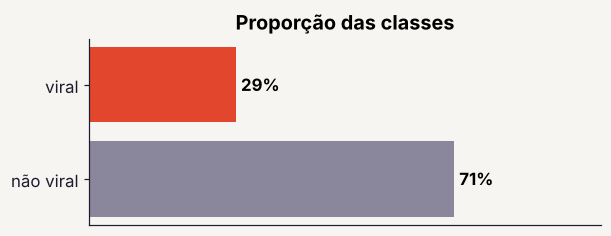

In [4]:
taxa = df.viral.mean()
print(f"Viralizaram: {df.viral.sum()} de {len(df)} vídeos  →  {taxa:.1%}")

fig, ax = plt.subplots(figsize=(6, 2.2))
ax.barh(["não viral", "viral"], [1 - taxa, taxa], color=[CINZA, SINAL])
for i, v in enumerate([1 - taxa, taxa]):
    ax.text(v + .01, i, f"{v:.0%}", va="center", fontweight="bold")
ax.set_xlim(0, 1); ax.set_title("Proporção das classes"); ax.set_xticks([])
plt.show()

> **Ideia-chave: desbalanceamento.** Só cerca de 29% dos vídeos viralizam (menos de 1 em cada 3). Isso importa muito: um modelo "preguiçoso" que **sempre** diz "não viral" já acertaria uns 71%. Vamos usar isso como linha de base na seção 7, e por isso não vamos confiar só na acurácia.

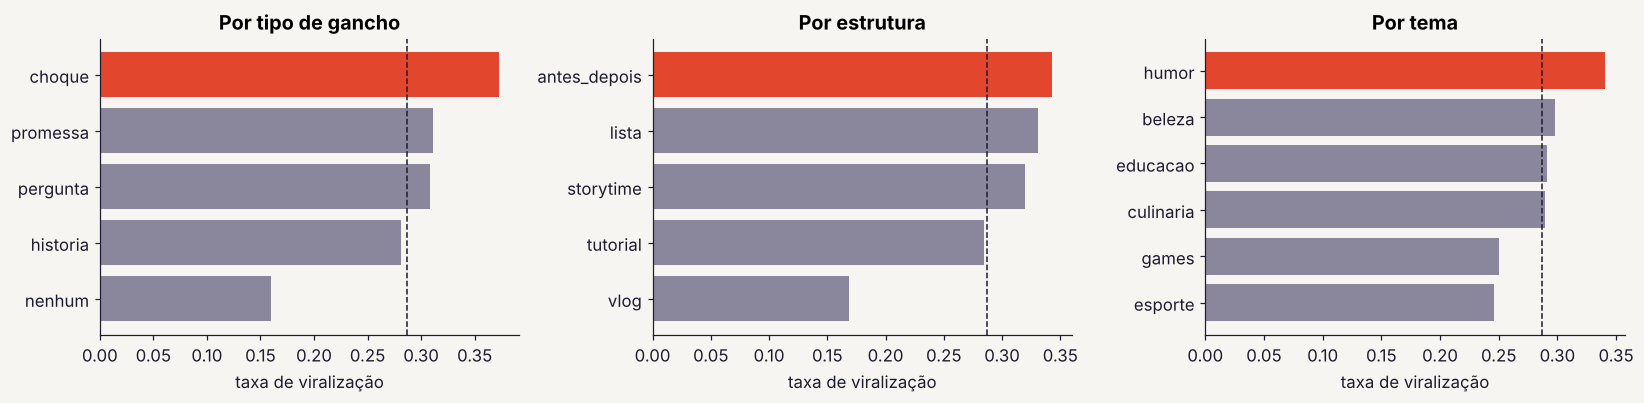

Linha tracejada = média geral


In [5]:
def taxa_por(coluna, ax, titulo):
    t = df.groupby(coluna).viral.mean().sort_values()
    cores = [SINAL if v == t.max() else CINZA for v in t]
    ax.barh(t.index.astype(str), t.values, color=cores)
    ax.axvline(taxa, color=TINTA, ls="--", lw=1)
    ax.set_title(titulo); ax.set_xlabel("taxa de viralização")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
taxa_por("tipo_hook", axes[0], "Por tipo de gancho")
taxa_por("estrutura", axes[1], "Por estrutura")
taxa_por("tema", axes[2], "Por tema")
plt.tight_layout(); plt.show()
print("Linha tracejada = média geral")

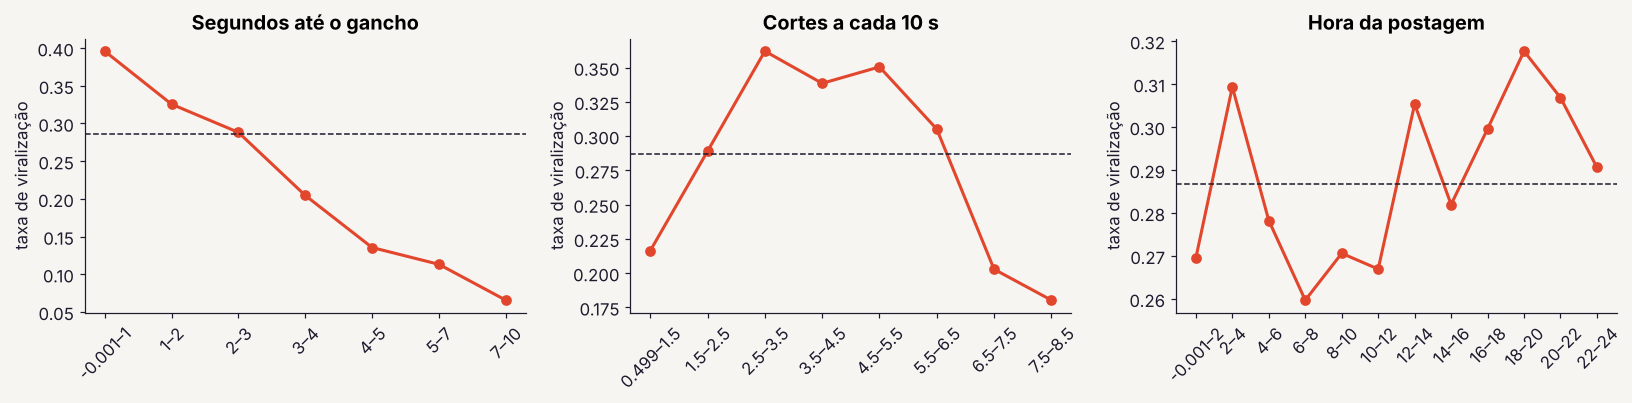

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col, bins, titulo in [
    (axes[0], "hook_segundos", [0, 1, 2, 3, 4, 5, 7, 10], "Segundos até o gancho"),
    (axes[1], "cortes_por_10s", np.arange(0.5, 8.6, 1), "Cortes a cada 10 s"),
    (axes[2], "hora_postagem", np.arange(0, 25, 2), "Hora da postagem"),
]:
    faixas = pd.cut(df[col], bins, include_lowest=True)
    t = df.groupby(faixas, observed=True).viral.mean()
    ax.plot(range(len(t)), t.values, marker="o", color=SINAL, lw=2)
    ax.set_xticks(range(len(t))); ax.set_xticklabels([f"{i.left:g}–{i.right:g}" for i in t.index], rotation=45)
    ax.axhline(taxa, color=TINTA, ls="--", lw=1); ax.set_title(titulo); ax.set_ylabel("taxa de viralização")
plt.tight_layout(); plt.show()

### O que os gráficos mostram
- **Gancho:** quanto mais o gancho demora, menor a chance. A queda é quase uma linha reta.
- **Cortes:** o formato é de **U invertido**. Pico perto de 4 cortes a cada 10 s; vídeos muito parados ou muito frenéticos vão pior.
- **Hora:** existe um "degrau" no começo da noite (18h–22h), não uma subida contínua.

> **Por que isso importa?** Alguns modelos (como a Regressão Logística) só enxergam relações em **linha reta**: "mais X → mais chance". Um U invertido ou um degrau confunde esse modelo. Na próxima seção vamos dar uma ajuda a ele.

<a id="4"></a>
## 4. Feature engineering: criando variáveis melhores

*Feature engineering* é usar o que aprendemos na exploração para **transformar** os dados de um jeito que o modelo entenda melhor. Criamos duas features novas:

| Nova feature | Fórmula | Por quê |
|---|---|---|
| `ritmo_fora_do_ideal` | `|cortes_por_10s − 4|` | transforma o U invertido em linha reta: quanto mais longe de 4, pior |
| `horario_nobre` | `1` se 18h ≤ hora ≤ 22h | transforma o degrau em um simples sim/não |
| `excesso_duracao` | `max(duracao − 30, 0)` | só conta os segundos que passam de 30 |

O número 4 e o limite de 30 s vieram **dos gráficos**, não das regras escondidas. É assim que se faria com dados reais.

In [7]:
def criar_features(d):
    d = d.copy()
    d["ritmo_fora_do_ideal"] = (d.cortes_por_10s - 4).abs()
    d["horario_nobre"] = d.hora_postagem.between(18, 22).astype(int)
    d["excesso_duracao"] = (d.duracao_seg - 30).clip(lower=0)
    return d

NUMERICAS = ["hook_segundos", "excesso_duracao", "ritmo_fora_do_ideal"]
BINARIAS = ["rosto_1s", "texto_na_tela", "tem_loop", "audio_em_alta", "horario_nobre"]
CATEGORICAS = ["tipo_hook", "estrutura", "tema"]
FEATURES = NUMERICAS + BINARIAS + CATEGORICAS

dados = criar_features(df)
X = dados[FEATURES]   # X = as perguntas (características)
y = dados["viral"]    # y = as respostas (viral ou não)
X.head()

,hook_segundos,excesso_duracao,ritmo_fora_do_ideal,rosto_1s,texto_na_tela,tem_loop,audio_em_alta,horario_nobre,tipo_hook,estrutura,tema
0,2.5,0,3.7,0,1,0,0,1,nenhum,tutorial,beleza
1,3.4,10,3.3,1,0,1,1,0,promessa,lista,beleza
2,2.2,39,2.7,0,1,0,0,1,choque,vlog,educacao
3,2.0,33,0.7,0,0,1,1,0,promessa,tutorial,beleza
4,3.7,35,0.4,1,0,0,0,0,promessa,antes_depois,culinaria


<a id="5"></a>
## 5. Separando treino e teste

Imagine estudar para uma prova **com as mesmas questões da prova**. Você tiraria 10, mas não aprendeu nada. Com modelos é igual: se medirmos o desempenho nos mesmos vídeos usados para treinar, o resultado engana.

Por isso dividimos:
- **80% treino** (2.400 vídeos): o modelo estuda aqui.
- **20% teste** (600 vídeos): ficam guardados numa gaveta e só são usados no final, como uma prova surpresa.

`stratify=y` garante que os dois grupos tenham a mesma proporção de virais (~29%).

In [8]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

print(f"Treino: {len(X_treino)} vídeos  ({y_treino.mean():.1%} virais)")
print(f"Teste:  {len(X_teste)} vídeos  ({y_teste.mean():.1%} virais)")

Treino: 2400 vídeos  (28.7% virais)
Teste:  600 vídeos  (28.7% virais)


<a id="6"></a>
## 6. Preparando os dados para o modelo

Modelos só entendem **números**. Temos dois problemas:

**Problema 1: texto.** `tipo_hook = "choque"` não é número. Solução: **One-Hot Encoding**, uma coluna 0/1 para cada opção.

| tipo_hook | → | hook_choque | hook_pergunta | hook_nenhum | ... |
|---|---|---|---|---|---|
| choque | | 1 | 0 | 0 | |
| pergunta | | 0 | 1 | 0 | |

**Problema 2: escalas diferentes.** `excesso_duracao` vai até 60, `hook_segundos` até 10. Sem ajuste, o modelo poderia achar que a primeira é "mais importante" só porque os números são maiores. Solução: **StandardScaler**, que transforma cada coluna para média 0 e desvio padrão 1: `z = (x − média) / desvio`.

As colunas 0/1 já estão numa escala boa, então passam direto (`passthrough`).

Tudo isso vai dentro de um **Pipeline**: uma "linha de montagem" que sempre aplica os mesmos passos, na mesma ordem. Isso evita um erro clássico: calcular a média usando os dados de teste (o que seria "espiar a prova").

In [9]:
preparo = ColumnTransformer([
    ("num", StandardScaler(), NUMERICAS),
    ("bin", "passthrough", BINARIAS),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAS),
])

# Mostra como fica um vídeo depois do preparo
preparo.fit(X_treino)
nomes = preparo.get_feature_names_out()
exemplo = pd.DataFrame(preparo.transform(X_treino.head(3)), columns=nomes).round(2)
print(f"De {X.shape[1]} colunas originais para {len(nomes)} colunas numéricas:")
exemplo.T

De 11 colunas originais para 24 colunas numéricas:


,0,1,2
num__hook_segundos,-0.96,-0.31,-0.48
num__excesso_duracao,0.65,-0.39,1.05
num__ritmo_fora_do_ideal,-0.91,-1.00,-0.81
bin__rosto_1s,1.00,1.00,1.00
bin__texto_na_tela,1.00,1.00,0.00
bin__tem_loop,0.00,0.00,1.00
bin__audio_em_alta,0.00,1.00,0.00
bin__horario_nobre,0.00,0.00,0.00
cat__tipo_hook_choque,0.00,0.00,0.00
cat__tipo_hook_historia,0.00,0.00,0.00


<a id="7"></a>
## 7. Treinando e comparando modelos

Vamos treinar 4 modelos, do mais bobo ao mais sofisticado:

| Modelo | Como pensa | Analogia |
|---|---|---|
| **Dummy** (linha de base) | sempre chuta a classe mais comum | o aluno que marca "C" em tudo |
| **Regressão Logística** | dá um **peso** para cada feature, soma tudo e passa pela sigmoide | uma balança: coisas boas de um lado, ruins do outro |
| **Árvore de Decisão** | faz uma sequência de perguntas sim/não | o jogo "Cara a Cara" |
| **Random Forest** | treina 300 árvores diferentes e faz uma votação | perguntar para 300 pessoas em vez de uma |

### Como medimos?
| Métrica | Pergunta que responde |
|---|---|
| **Acurácia** | de todos os vídeos, quantos % acertou? |
| **Precisão** | quando o modelo diz "vai viralizar", quantas vezes está certo? |
| **Recall** | dos vídeos que viralizaram de verdade, quantos o modelo encontrou? |
| **F1** | equilíbrio entre precisão e recall |
| **AUC** | o modelo sabe **ordenar** os vídeos do menos para o mais viral? (0,5 = chute, 1,0 = perfeito) |

In [10]:
modelos = {
    "Dummy (sempre 'não')": DummyClassifier(strategy="most_frequent"),
    "Regressão Logística":  LogisticRegression(max_iter=1000),
    "Árvore de Decisão":    DecisionTreeClassifier(max_depth=4, random_state=SEED),
    "Random Forest":        RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEED),
}

resultados, treinados = [], {}
for nome, modelo in modelos.items():
    pipe = Pipeline([("preparo", preparo), ("modelo", modelo)])
    pipe.fit(X_treino, y_treino)                    # ← o aprendizado acontece aqui
    prev = pipe.predict(X_teste)                    # classe prevista (0 ou 1)
    prob = pipe.predict_proba(X_teste)[:, 1]        # probabilidade de ser viral
    treinados[nome] = pipe
    resultados.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_teste, prev),
        "Precisão": precision_score(y_teste, prev, zero_division=0),
        "Recall": recall_score(y_teste, prev),
        "F1": f1_score(y_teste, prev),
        "AUC": roc_auc_score(y_teste, prob),
    })

tabela = pd.DataFrame(resultados).set_index("Modelo").round(3)
tabela.style.background_gradient(cmap="Oranges", subset=["F1", "AUC"]).format("{:.3f}")

,Acurácia,Precisão,Recall,F1,AUC
Modelo,,,,,
Dummy (sempre 'não'),0.713,0.000,0.000,0.000,0.500
Regressão Logística,0.745,0.602,0.326,0.423,0.772
Árvore de Decisão,0.728,0.533,0.419,0.469,0.710
Random Forest,0.750,0.704,0.221,0.336,0.772


### Lendo a tabela
- O **Dummy** tem acurácia alta (~71%) mas recall **zero**: nunca encontra um vídeo viral. Prova de que acurácia sozinha engana.
- Os modelos de verdade têm AUC bem acima de 0,5, ou seja, **aprenderam algo real**.
- A **Regressão Logística** empata com a Random Forest na AUC do teste (0,77), mesmo sendo muito mais simples, e ganha na validação cruzada logo abaixo. Faz sentido: depois do *feature engineering* as relações ficaram em linha reta, que é exatamente o que ela modela.
- O recall de todos parece baixo. Isso é efeito do **limiar de 50%**, que vamos discutir na seção 8: o modelo só diz "viral" quando está muito confiante.

> **Lição:** o modelo mais complexo nem sempre é o melhor. Escolhemos a **Regressão Logística** porque ela é a melhor aqui **e** dá para explicar cada decisão dela (seção 9).

### Validação cruzada: o resultado foi sorte?
Um único teste de 600 vídeos pode ter dado sorte. Na **validação cruzada (5-fold)** dividimos o treino em 5 partes, treinamos 5 vezes deixando uma parte diferente de fora e tiramos a média.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for nome in ["Regressão Logística", "Árvore de Decisão", "Random Forest"]:
    notas = cross_val_score(treinados[nome], X_treino, y_treino, cv=cv, scoring="roc_auc")
    print(f"{nome:22s} AUC = {notas.mean():.3f} ± {notas.std():.3f}   {np.round(notas, 3)}")

Regressão Logística    AUC = 0.750 ± 0.037   [0.775 0.785 0.697 0.714 0.781]
Árvore de Decisão      AUC = 0.654 ± 0.023   [0.661 0.682 0.616 0.642 0.671]


Random Forest          AUC = 0.735 ± 0.026   [0.741 0.766 0.706 0.705 0.759]


O "±" pequeno mostra que o desempenho é estável: não foi sorte de uma divisão específica.

### Bônus: olhando dentro da Árvore de Decisão
A árvore é o modelo mais fácil de visualizar. Cada caixa é uma pergunta; seguindo os galhos você chega numa previsão. Mostramos só os 2 primeiros níveis.

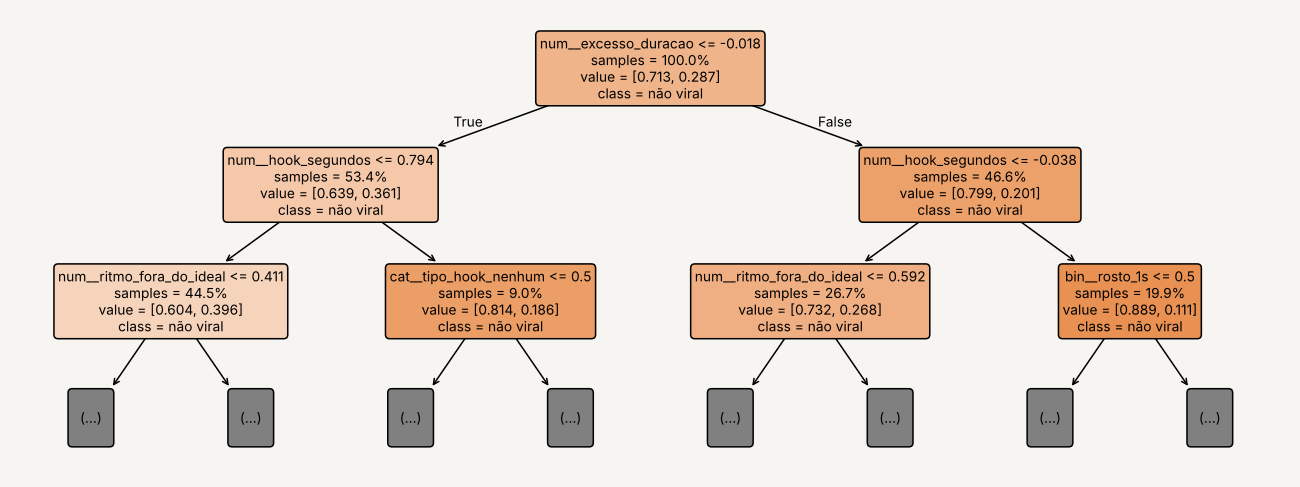

Primeira pergunta da árvore: num__excesso_duracao


In [12]:
arvore = treinados["Árvore de Decisão"]
fig, ax = plt.subplots(figsize=(15, 5.5))
plot_tree(arvore.named_steps["modelo"], max_depth=2, feature_names=list(nomes),
          class_names=["não viral", "viral"], filled=True, rounded=True, fontsize=9,
          impurity=False, proportion=True, ax=ax)
plt.show()
raiz = arvore.named_steps["modelo"].tree_.feature[0]
print("Primeira pergunta da árvore:", nomes[raiz])

A **primeira pergunta** da árvore é a feature que ela achou mais útil para separar virais de não virais. Aqui ela começa pela **duração** (`excesso_duracao`, os segundos além de 30): vídeos longos demais quase nunca viralizam, então essa é a separação mais "limpa" que a árvore encontrou. Logo abaixo vêm perguntas sobre o gancho.

<a id="8"></a>
## 8. Avaliando o modelo escolhido

### Matriz de confusão
Mostra **onde** o modelo acerta e erra, nos 600 vídeos de teste.

|  | Previu "não viral" | Previu "viral" |
|---|---|---|
| **Era não viral** | Verdadeiro Negativo ✔ | Falso Positivo (alarme falso) |
| **Era viral** | Falso Negativo (deixou passar) | Verdadeiro Positivo ✔ |

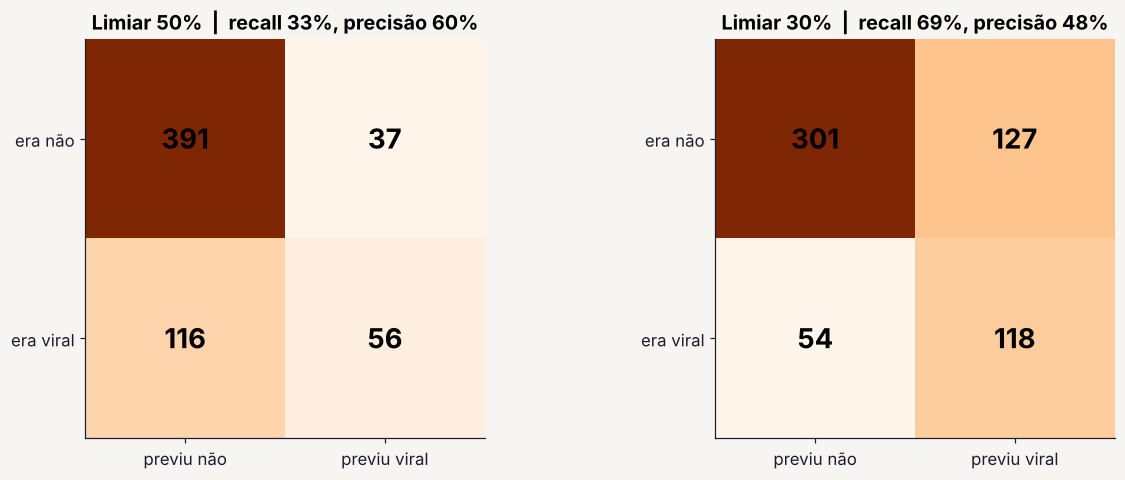

In [13]:
melhor = treinados["Regressão Logística"]
prob_teste = melhor.predict_proba(X_teste)[:, 1]

def mostrar_matriz(limiar, ax):
    prev = (prob_teste >= limiar).astype(int)
    m = confusion_matrix(y_teste, prev)
    ax.imshow(m, cmap="Oranges")
    for (i, j), v in np.ndenumerate(m):
        ax.text(j, i, v, ha="center", va="center", fontsize=18, fontweight="bold")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["previu não", "previu viral"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["era não", "era viral"])
    ax.set_title(f"Limiar {limiar:.0%}  |  recall {recall_score(y_teste, prev):.0%}, precisão {precision_score(y_teste, prev):.0%}")
    return m

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
mostrar_matriz(0.5, axes[0]); mostrar_matriz(0.3, axes[1])
plt.tight_layout(); plt.show()

### O limiar (threshold)
O modelo dá uma probabilidade. Por padrão, acima de **50%** ele diz "viral". Mas esse número é uma escolha nossa:
- **Limiar 50%:** o modelo só aposta quando está bem confiante. Menos alarmes falsos, mas deixa muitos virais passarem.
- **Limiar 30%:** encontra muito mais virais (recall sobe), ao custo de mais alarmes falsos.

Para um criador, perder um vídeo com potencial é pior do que um alarme falso, então um limiar mais baixo faz sentido. **Não existe limiar certo; depende do uso.**

### Curva ROC
Testa **todos** os limiares de uma vez. Quanto mais a curva se afasta da diagonal (chute), melhor. A área embaixo dela é a **AUC**.

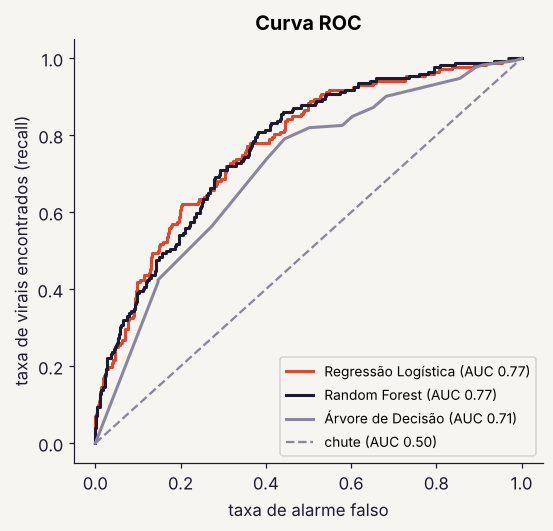

In [14]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for nome, cor in [("Regressão Logística", SINAL), ("Random Forest", TINTA), ("Árvore de Decisão", CINZA)]:
    p = treinados[nome].predict_proba(X_teste)[:, 1]
    fpr, tpr, _ = roc_curve(y_teste, p)
    ax.plot(fpr, tpr, color=cor, lw=2, label=f"{nome} (AUC {roc_auc_score(y_teste, p):.2f})")
ax.plot([0, 1], [0, 1], ls="--", color=CINZA, label="chute (AUC 0.50)")
ax.set_xlabel("taxa de alarme falso"); ax.set_ylabel("taxa de virais encontrados (recall)")
ax.set_title("Curva ROC"); ax.legend(fontsize=9, loc="lower right")
plt.show()

<a id="9"></a>
## 9. Por que o modelo decide o que decide?

A Regressão Logística aprendeu **um peso para cada coluna**. A fórmula que ela usa é:

$$
\text{pontos} = b + w_1 x_1 + w_2 x_2 + \dots + w_n x_n \qquad\qquad P(\text{viral}) = \frac{1}{1 + e^{-\text{pontos}}}
$$

- **Peso positivo** → aquela característica **aumenta** a chance.
- **Peso negativo** → **diminui**.
- Quanto maior o número (em valor absoluto), mais forte o efeito.

O "treino" é o computador testando milhares de combinações de pesos (com um método chamado *gradiente descendente*) até achar os que mais acertam nos 2.400 vídeos de treino.

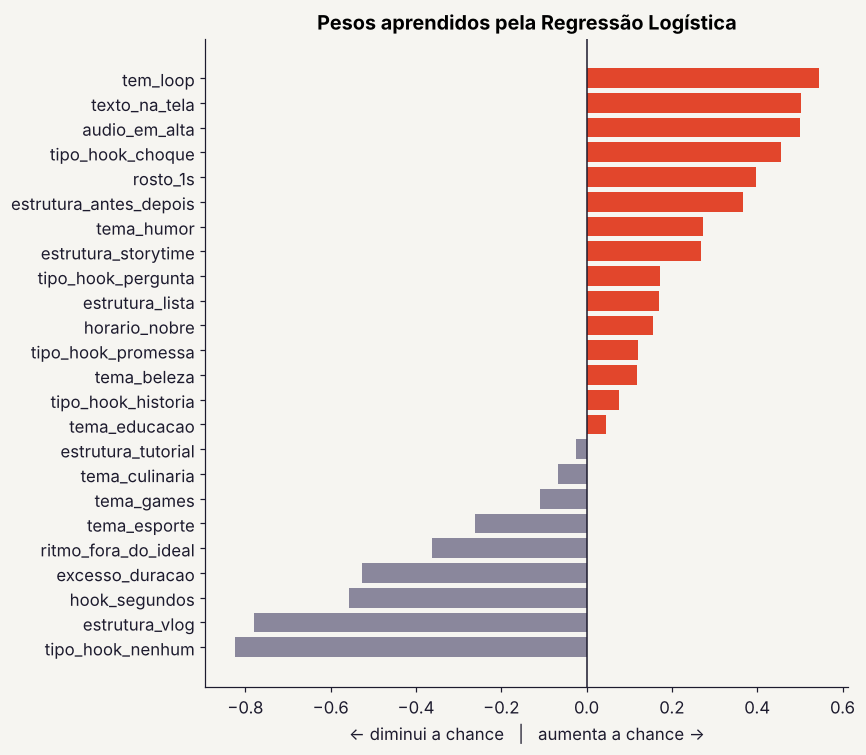

Intercepto (b): -1.97


In [15]:
lr = melhor.named_steps["modelo"]
pesos = pd.Series(lr.coef_[0], index=nomes).sort_values()
rotulos = [n.split("__")[1] for n in pesos.index]

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(rotulos, pesos.values, color=[SINAL if v > 0 else CINZA for v in pesos.values])
ax.axvline(0, color=TINTA, lw=1)
ax.set_title("Pesos aprendidos pela Regressão Logística"); ax.set_xlabel("← diminui a chance   |   aumenta a chance →")
plt.tight_layout(); plt.show()
print(f"Intercepto (b): {lr.intercept_[0]:.2f}")

### O modelo redescobriu as regras?
Comparando com as regras escondidas da seção 2:
- `hook_segundos` tem peso **negativo** forte → demorar no gancho atrapalha. ✔
- `tipo_hook_nenhum` e `estrutura_vlog` são os mais negativos entre as categorias. ✔
- `tem_loop`, `audio_em_alta` e `tipo_hook_choque` são positivos. ✔
- `ritmo_fora_do_ideal` e `excesso_duracao` são negativos. ✔

O modelo **nunca viu a fórmula**, só 2.400 exemplos com ruído, e mesmo assim chegou nas mesmas conclusões. Isso é machine learning funcionando.

> **Cuidado ao interpretar:** pesos de colunas padronizadas (`num__`) estão em "desvios padrão", e os das colunas 0/1 em "ter vs. não ter". Dá para comparar a direção, mas o tamanho só é comparável dentro do mesmo grupo.

<a id="10"></a>
## 10. Prevendo um vídeo novo

Agora a parte divertida: descrevemos um vídeo que ainda não foi postado e perguntamos ao modelo.

In [16]:
def prever_video(**video):
    linha = criar_features(pd.DataFrame([video]))[FEATURES]
    return melhor.predict_proba(linha)[0, 1]

video_a = dict(hook_segundos=0.8, tipo_hook="choque", rosto_1s=1, texto_na_tela=1,
               duracao_seg=22, cortes_por_10s=4.2, estrutura="antes_depois", tem_loop=1,
               tema="humor", audio_em_alta=1, hora_postagem=19)

video_b = dict(hook_segundos=6.0, tipo_hook="nenhum", rosto_1s=0, texto_na_tela=0,
               duracao_seg=75, cortes_por_10s=0.8, estrutura="vlog", tem_loop=0,
               tema="esporte", audio_em_alta=0, hora_postagem=9)

print(f"Vídeo A (gancho forte, curto, loop):     {prever_video(**video_a):.1%} de chance de viralizar")
print(f"Vídeo B (sem gancho, longo, parado):     {prever_video(**video_b):.1%} de chance de viralizar")

Vídeo A (gancho forte, curto, loop):     94.7% de chance de viralizar
Vídeo B (sem gancho, longo, parado):     0.2% de chance de viralizar


> **Experimente:** mude um valor de cada vez no `video_b` (por exemplo, `hook_segundos=1`) e rode de novo. Você vai ver o quanto cada mudança sozinha ajuda. O site faz exatamente isso, com controles deslizantes.

<a id="11"></a>
## 11. Exportando o modelo para o site

O site não roda Python. Mas como a Regressão Logística é só uma fórmula (pesos + sigmoide), basta salvar os números aprendidos num arquivo e refazer a mesma conta em JavaScript.

Salvamos também a média de cada coluna no treino: assim o site consegue dizer "comparado a um vídeo médio, esta escolha somou ou tirou X pontos".

In [17]:
esc = melhor.named_steps["preparo"].named_transformers_["num"]
ohe = melhor.named_steps["preparo"].named_transformers_["cat"]
coef = dict(zip(nomes, lr.coef_[0]))
medias = dict(zip(nomes, preparo.transform(X_treino).mean(axis=0)))

m05 = confusion_matrix(y_teste, (prob_teste >= .5).astype(int))
export = {
    "intercepto": float(lr.intercept_[0]),
    "numericas": {f: {"media": float(esc.mean_[i]), "desvio": float(esc.scale_[i]), "peso": float(coef[f"num__{f}"])}
                  for i, f in enumerate(NUMERICAS)},
    "binarias": {f: {"peso": float(coef[f"bin__{f}"]), "media": float(medias[f"bin__{f}"])} for f in BINARIAS},
    "categoricas": {f: {str(c): {"peso": float(coef[f"cat__{f}_{c}"]), "media": float(medias[f"cat__{f}_{c}"])}
                        for c in cats} for f, cats in zip(CATEGORICAS, ohe.categories_)},
    "metricas": {k: float(v) for k, v in tabela.loc["Regressão Logística"].items()},
    "comparacao": {n: {k: float(v) for k, v in r.items()} for n, r in tabela.iterrows()},
    "matriz": m05.tolist(),
    "dados": {"total": len(df), "treino": len(X_treino), "teste": len(X_teste), "taxa_viral": float(taxa),
              "taxa_por_hook": df.groupby("tipo_hook").viral.mean().round(3).to_dict(),
              "taxa_por_gancho_seg": {f"{i.left:g}–{i.right:g}": round(float(v), 3) for i, v in
                  df.groupby(pd.cut(df.hook_segundos, [0, 1, 2, 3, 4, 5, 7, 10], include_lowest=True), observed=True).viral.mean().items()}},
}

# Conferência: a fórmula exportada dá o mesmo resultado que o scikit-learn?
def prever_pela_formula(v):
    d = criar_features(pd.DataFrame([v])).iloc[0]
    z = export["intercepto"]
    z += sum(p["peso"] * (d[f] - p["media"]) / p["desvio"] for f, p in export["numericas"].items())
    z += sum(p["peso"] * d[f] for f, p in export["binarias"].items())
    z += sum(export["categoricas"][f][d[f]]["peso"] for f in CATEGORICAS)
    return sigmoid(z)
assert abs(prever_pela_formula(video_a) - prever_video(**video_a)) < 1e-9

os.makedirs("../site", exist_ok=True)
with open("../site/model.js", "w", encoding="utf-8") as f:
    f.write("// Gerado automaticamente pelo notebook (seção 11). Não edite à mão.\n")
    f.write("window.MODELO = " + json.dumps(export, ensure_ascii=False, indent=1) + ";\n")
print("Modelo exportado para site/model.js  ✔  (fórmula conferida com o scikit-learn)")

Modelo exportado para site/model.js  ✔  (fórmula conferida com o scikit-learn)


<a id="12"></a>
## 12. Limitações e próximos passos

Um bom projeto de ciência de dados é honesto sobre o que **não** sabe.

1. **Os dados são sintéticos.** O modelo aprendeu as regras que nós escrevemos. Para valer no mundo real, seria preciso assistir e anotar centenas de vídeos de verdade. A estrutura do notebook continua a mesma: é só trocar o arquivo `videos.csv`.
2. **Correlação não é causa.** Mesmo com dados reais, "vídeos com loop viralizam mais" não prova que **colocar** um loop faz viralizar. Talvez criadores experientes usem mais loops e também façam vídeos melhores em outros aspectos.
3. **Faltam fatores enormes:** tamanho do perfil, o algoritmo da plataforma, timing com tendências, qualidade da ideia. Por isso, mesmo nos dados sintéticos, existe o fator "sorte" que nenhum modelo prevê.
4. **"Viral" é uma definição.** Aqui é 0 ou 1. Na prática teríamos que escolher um corte (ex.: 10x a média de views do perfil).

**Próximos passos:** coletar ~300 vídeos reais anotados à mão, testar se as mesmas features continuam importantes, e experimentar prever o número de visualizações (regressão) em vez de só sim/não.

---

## Resumo em uma frase
> Demos 2.400 exemplos de vídeos para um modelo de Regressão Logística; ele aprendeu quanto cada característica pesa, acertou a ordem dos vídeos em 77% das comparações (AUC 0,77) nos 600 vídeos que nunca tinha visto, e descobriu sozinho que **o gancho e a duração são o que mais pesam**.

## Glossário rápido
**Feature:** característica usada para prever · **Target:** o que se quer prever · **Treino/Teste:** dados para aprender / para avaliar · **Overfitting:** decorar o treino e ir mal no teste · **One-Hot:** transformar categorias em colunas 0/1 · **Padronização:** colocar números na mesma escala · **Sigmoide:** função que transforma pontos em probabilidade · **Limiar:** probabilidade a partir da qual dizemos "viral" · **AUC:** chance de o modelo dar nota maior a um vídeo viral do que a um não viral.